In [ ]:
# 8. Construct a CNN model for Sign Language alphabet recognition. 
# Normalize the image pixels, train the model using the training dataset and 
# display training accuracy, testing accuracy and loss graph.

In [1]:
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

In [2]:
train_data = pd.read_csv('sign_mnist_train.csv')
test_data = pd.read_csv('sign_mnist_test.csv')

print(train_data.shape)
print(test_data.shape)

(27455, 785)
(7172, 785)


In [3]:
X_train = train_data.drop('label', axis=1).values
y_train = train_data['label'].values

X_test = test_data.drop('label', axis=1).values
y_test = test_data['label'].values

In [4]:
# Convert labels into 24 classes

classes = np.sort(np.unique(y_train))
label_map = {label: i for i, label in enumerate(classes)}

y_train = np.array([label_map[x] for x in y_train])
y_test = np.array([label_map[x] for x in y_test])

# Normalize images

X_train = X_train / 255.0
X_test = X_test / 255.0

# Reshape images

X_train = X_train.reshape(-1, 28, 28, 1)
X_test = X_test.reshape(-1, 28, 28, 1)

print("Training Shape:", X_train.shape)
print("Testing Shape:", X_test.shape)

Training Shape: (27455, 28, 28, 1)
Testing Shape: (7172, 28, 28, 1)


In [5]:
model = tf.keras.Sequential([

    tf.keras.layers.Input(shape=(28, 28, 1)),

    tf.keras.layers.Conv2D(32, (3,3), activation='relu'),

    tf.keras.layers.MaxPooling2D((2,2)),

    tf.keras.layers.Conv2D(64, (3,3), activation='relu'),

    tf.keras.layers.MaxPooling2D((2,2)),

    tf.keras.layers.Flatten(),

    tf.keras.layers.Dense(128, activation='relu'),

    tf.keras.layers.Dense(24, activation='softmax')
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 26, 26, 32)          │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 13, 13, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 11, 11, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 5, 5, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 1600)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │         204,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 24)                  │           3,096 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 226,840 (886.09 KB)

 Trainable params: 226,840 (886.09 KB)

 Non-trainable params: 0 (0.00 B)

In [6]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [7]:
history = model.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=128,
    validation_split=0.2
)

Epoch 1/10
172/172 ━━━━━━━━━━━━━━━━━━━━ 6s 30ms/step - accuracy: 0.4452 - loss: 1.8922 - val_accuracy: 0.7764 - val_loss: 0.7591
Epoch 2/10
172/172 ━━━━━━━━━━━━━━━━━━━━ 8s 21ms/step - accuracy: 0.8615 - loss: 0.4859 - val_accuracy: 0.9213 - val_loss: 0.2801
Epoch 3/10
172/172 ━━━━━━━━━━━━━━━━━━━━ 4s 21ms/step - accuracy: 0.9589 - loss: 0.1784 - val_accuracy: 0.9774 - val_loss: 0.1004
Epoch 4/10
172/172 ━━━━━━━━━━━━━━━━━━━━ 4s 20ms/step - accuracy: 0.9916 - loss: 0.0659 - val_accuracy: 0.9969 - val_loss: 0.0395
Epoch 5/10
172/172 ━━━━━━━━━━━━━━━━━━━━ 4s 22ms/step - accuracy: 0.9992 - loss: 0.0249 - val_accuracy: 0.9996 - val_loss: 0.0204
Epoch 6/10
172/172 ━━━━━━━━━━━━━━━━━━━━ 5s 21ms/step - accuracy: 0.9999 - loss: 0.0123 - val_accuracy: 0.9998 - val_loss: 0.0091
Epoch 7/10
172/172 ━━━━━━━━━━━━━━━━━━━━ 4s 23ms/step - accuracy: 1.0000 - loss: 0.0073 - val_accuracy: 1.0000 - val_loss: 0.0056
Epoch 8/10
172/172 ━━━━━━━━━━━━━━━━━━━━ 4s 23ms/step - accuracy: 1.0000 - loss: 0.0048 - val_accu

In [8]:
# Training Accuracy

train_accuracy = history.history['accuracy'][-1]

# Testing Accuracy

test_loss, test_accuracy = model.evaluate(X_test, y_test)

print("Training Accuracy: {:.2f}%".format(train_accuracy * 100))
print("Testing Accuracy: {:.2f}%".format(test_accuracy * 100))

225/225 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8972 - loss: 0.4350
Training Accuracy: 100.00%
Testing Accuracy: 89.72%


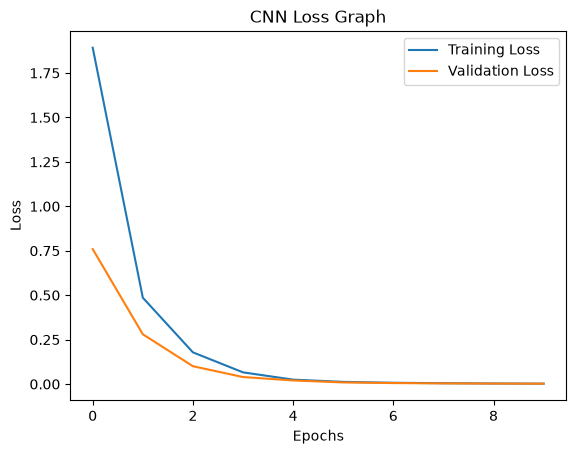

In [9]:
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title('CNN Loss Graph')
plt.xlabel('Epochs')
plt.ylabel('Loss')

plt.legend()
plt.show()